In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [3]:
df = pd.read_csv(r"D:\NTI Machine\Preprocessing\cars_data.csv")

In [4]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [5]:
df.duplicated().sum()

0

In [6]:
df.isnull().sum()

Brand               0
Year                0
Mileage             0
Engine_Size        20
Fuel_Type           0
Transmission        0
Previous_Owners     0
Price               0
dtype: int64

In [7]:
df[df['Engine_Size'].isnull()].head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
21,Nissan,2023,94431,NaN,Hybrid,Manual,4,8973
123,Kia,2017,166633,NaN,Hybrid,Automatic,2,4631
326,BMW,2012,101347,NaN,Diesel,Automatic,5,9410
400,Mazda,2023,7356,NaN,Diesel,Manual,1,14328
435,Mazda,2014,36585,NaN,Petrol,Automatic,5,4832


In [8]:
df.groupby(['Engine_Size','Year','Fuel_Type','Transmission'])['Engine_Size']

In [9]:
df['Engine_Size'] = df.groupby(['Year','Fuel_Type','Transmission'])['Engine_Size']\
                      .transform(lambda x: x.fillna(x.mode()[0] ))


In [10]:
df.isnull().sum()

Brand              0
Year               0
Mileage            0
Engine_Size        0
Fuel_Type          0
Transmission       0
Previous_Owners    0
Price              0
dtype: int64

In [11]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [12]:
for col in df.select_dtypes('object').columns:
    print(f"{col} Uniques count: ",df[col].nunique())
    print(f"{col} uniques: " , df[col].unique())
    print("_" * 50)

Brand Uniques count:  8
Brand uniques:  ['Kia' 'Mercedes' 'Nissan' 'BMW' 'Mazda' 'Honda' 'Hyundai' 'Toyota']
__________________________________________________
Fuel_Type Uniques count:  4
Fuel_Type uniques:  ['Electric' 'Petrol' 'Diesel' 'Hybrid']
__________________________________________________
Transmission Uniques count:  2
Transmission uniques:  ['Manual' 'Automatic']
__________________________________________________


In [13]:

df['Transmission'] = df['Transmission'].apply(lambda x : int(x == 'Manual'))
#Manual = 1 ,Automatic = 0

In [14]:
df


,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,1,2,3000
1,Mercedes,2010,186144,1.3,Electric,1,5,4844
2,Nissan,2018,29574,2.6,Petrol,1,1,6628
3,Kia,2010,139502,2.4,Diesel,0,4,3000
4,BMW,2014,148748,3.5,Diesel,1,1,6451
...,...,...,...,...,...,...,...,...
995,Nissan,2018,21052,1.8,Electric,0,4,13831
996,Toyota,2017,105689,2.0,Hybrid,1,2,6296
997,Mercedes,2021,183148,3.8,Hybrid,0,2,19708
998,Mazda,2018,189492,1.9,Diesel,0,5,3283


<Axes: xlabel='Mileage', ylabel='Price'>

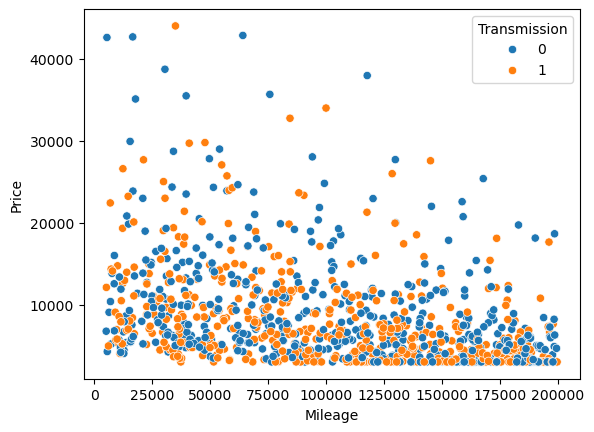

In [15]:
sns.scatterplot(data = df, x = 'Mileage', y = 'Price',hue = 'Transmission')

In [16]:
df

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,1,2,3000
1,Mercedes,2010,186144,1.3,Electric,1,5,4844
2,Nissan,2018,29574,2.6,Petrol,1,1,6628
3,Kia,2010,139502,2.4,Diesel,0,4,3000
4,BMW,2014,148748,3.5,Diesel,1,1,6451
...,...,...,...,...,...,...,...,...
995,Nissan,2018,21052,1.8,Electric,0,4,13831
996,Toyota,2017,105689,2.0,Hybrid,1,2,6296
997,Mercedes,2021,183148,3.8,Hybrid,0,2,19708
998,Mazda,2018,189492,1.9,Diesel,0,5,3283


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns="Price")
y = df["Price"]

categorical_features = ["Brand", "Fuel_Type"]
numeric_features = [
    "Year", "Mileage", "Engine_Size", "Transmission", "Previous_Owners"
]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", StandardScaler(), numeric_features),
])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [18]:
X_train

array([[ 0.        ,  0.        ,  0.        , ...,  0.47694741,
        -0.97530483, -0.74033073],
       [ 0.        ,  0.        ,  1.        , ..., -1.03164536,
         1.02532046, -0.02847426],
       [ 0.        ,  0.        ,  0.        , ...,  0.24485621,
         1.02532046,  1.39523869],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.79955417,
        -0.97530483, -1.4521872 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.79955417,
        -0.97530483,  1.39523869],
       [ 0.        ,  1.        ,  0.        , ...,  0.8250842 ,
        -0.97530483,  1.39523869]])

In [19]:
X_test

array([[ 0.        ,  0.        ,  0.        , ..., -1.37978215,
        -0.97530483, -0.02847426],
       [ 0.        ,  0.        ,  0.        , ...,  0.01276502,
        -0.97530483, -0.74033073],
       [ 0.        ,  0.        ,  0.        , ...,  1.28926659,
         1.02532046,  1.39523869],
       ...,
       [ 0.        ,  0.        ,  1.        , ...,  0.36090181,
        -0.97530483, -0.74033073],
       [ 0.        ,  1.        ,  0.        , ...,  0.592993  ,
        -0.97530483, -0.02847426],
       [ 0.        ,  0.        ,  0.        , ...,  0.592993  ,
         1.02532046, -0.02847426]])

In [22]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [23]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [25]:
from tqdm import tqdm

  0%|          | 0/15 [00:00<?, ?it/s]

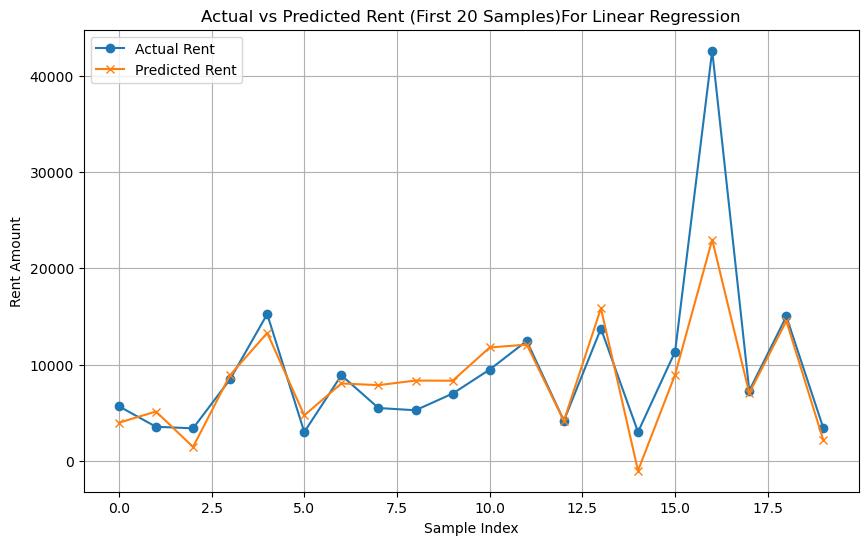

  7%|▋         | 1/15 [00:00<00:05,  2.71it/s]

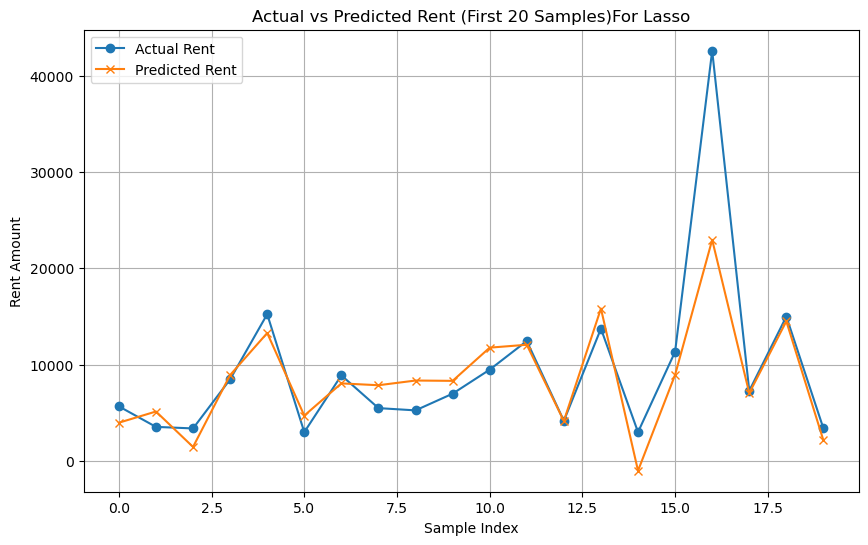

 13%|█▎        | 2/15 [00:00<00:03,  3.29it/s]

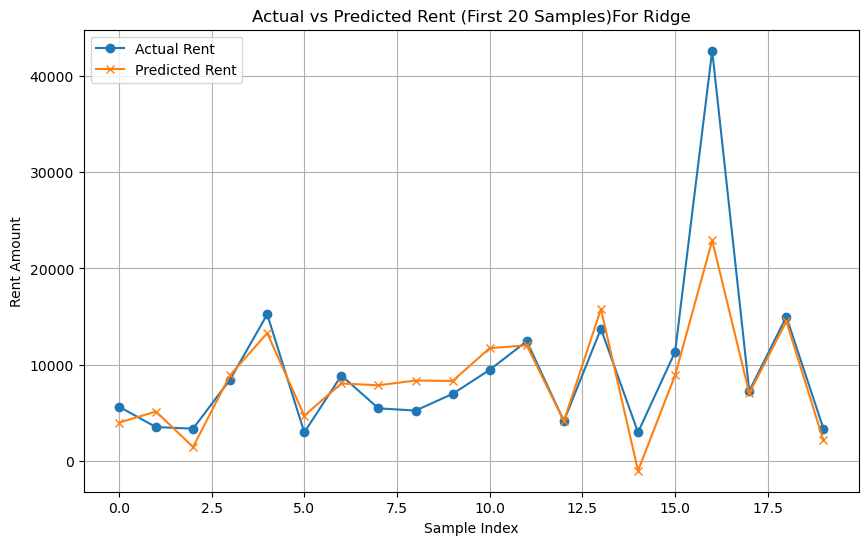

 20%|██        | 3/15 [00:00<00:03,  3.29it/s]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar

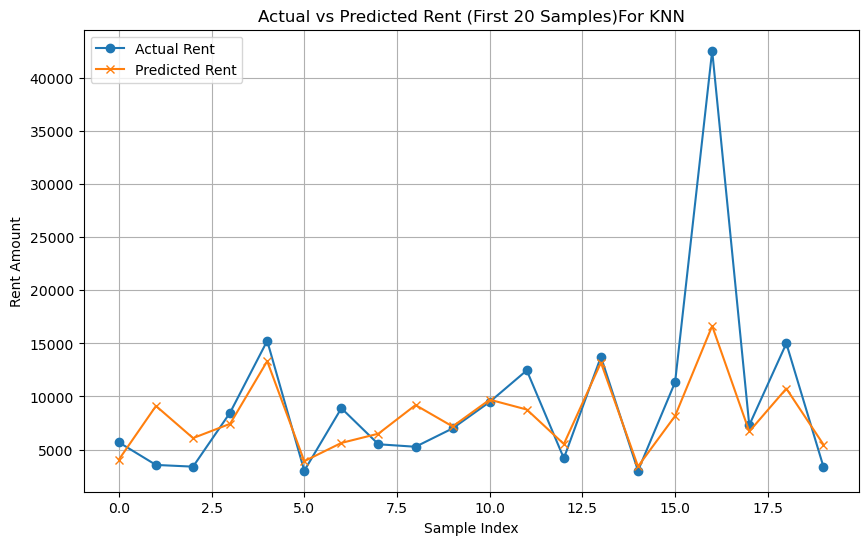

 27%|██▋       | 4/15 [00:01<00:04,  2.39it/s]

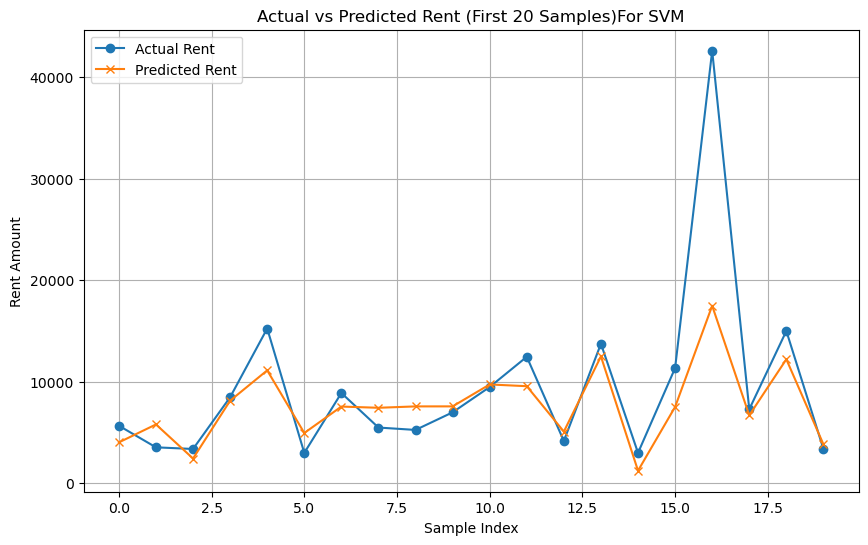

 33%|███▎      | 5/15 [00:01<00:03,  2.51it/s]

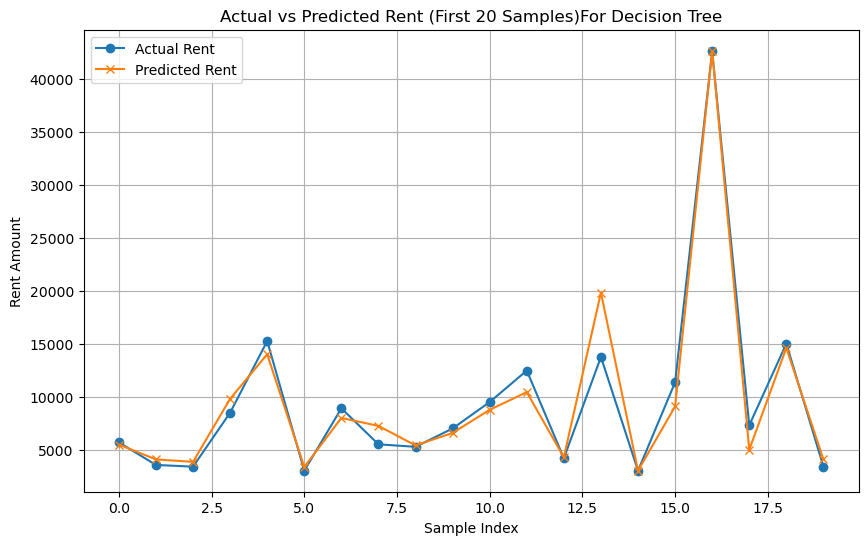

 40%|████      | 6/15 [00:02<00:03,  2.91it/s]

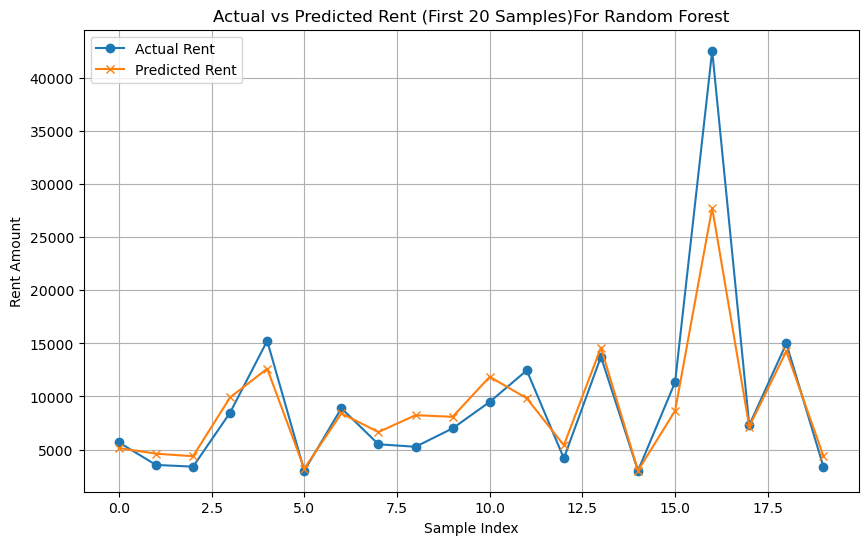

 47%|████▋     | 7/15 [00:02<00:03,  2.55it/s]

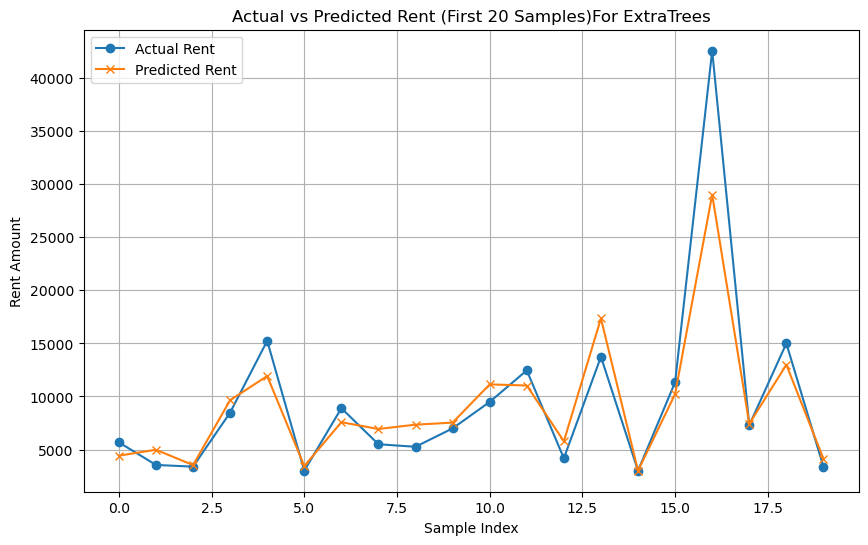

 53%|█████▎    | 8/15 [00:03<00:03,  2.05it/s]

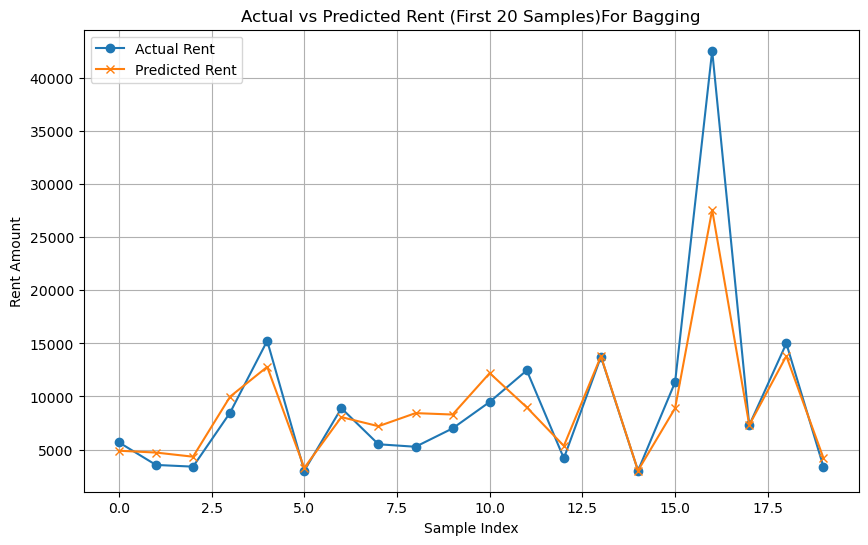

 60%|██████    | 9/15 [00:03<00:02,  2.04it/s]

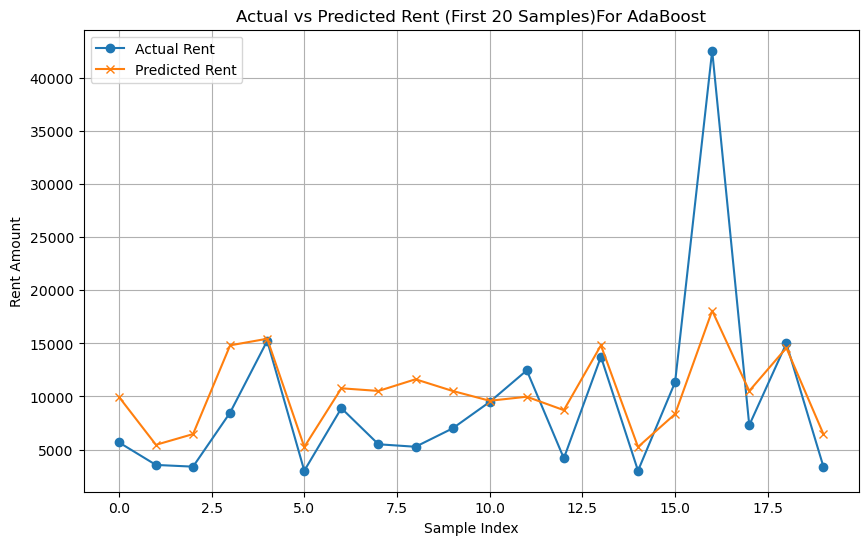

 67%|██████▋   | 10/15 [00:04<00:02,  2.15it/s]

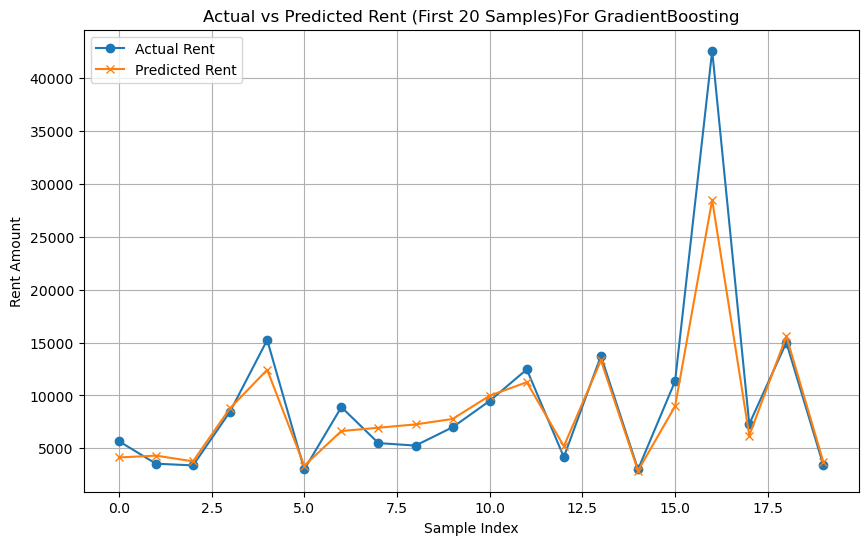

 73%|███████▎  | 11/15 [00:04<00:02,  1.96it/s]

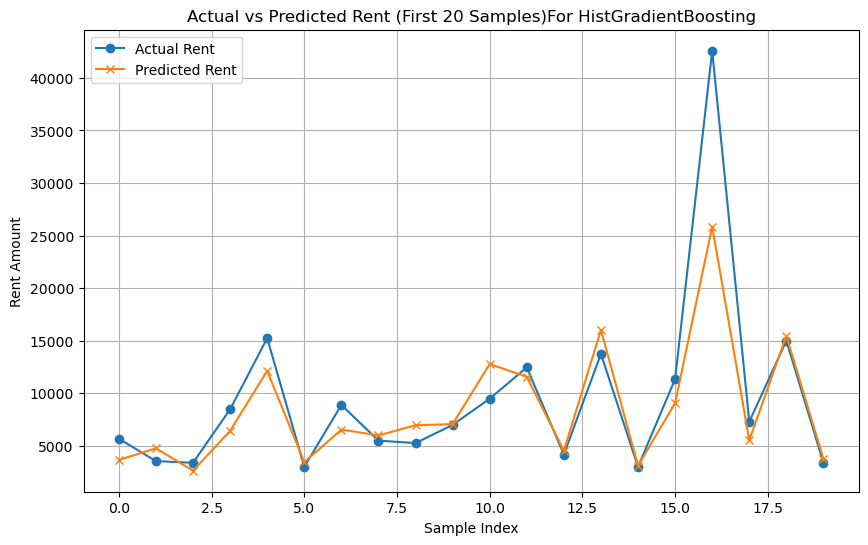

 80%|████████  | 12/15 [00:13<00:09,  3.07s/it]

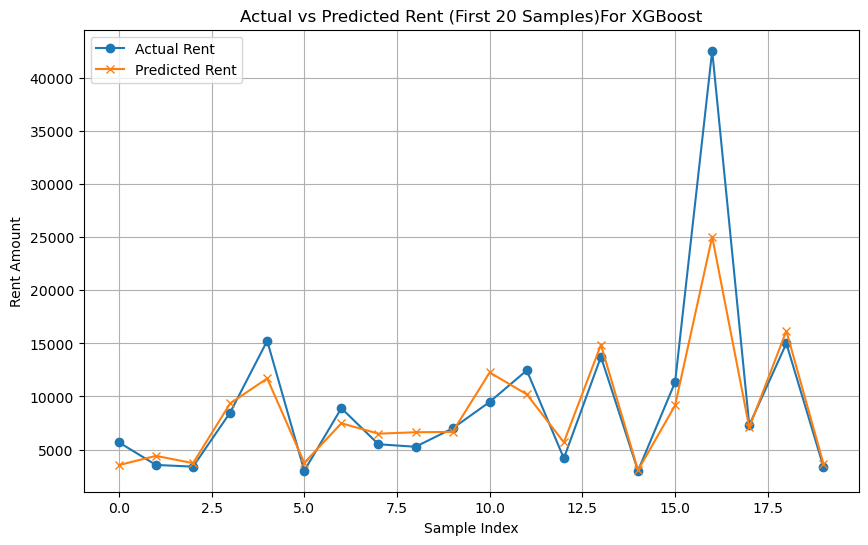

 87%|████████▋ | 13/15 [00:15<00:05,  2.78s/it]

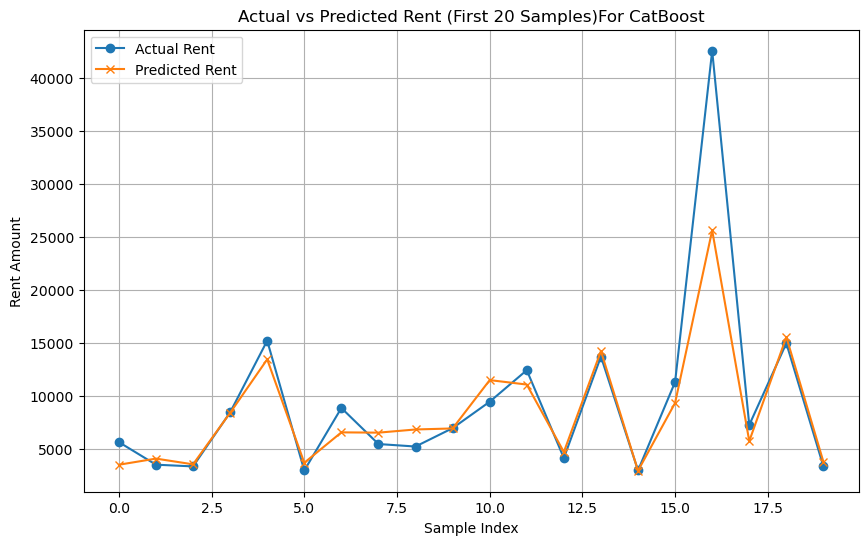

 93%|█████████▎| 14/15 [00:16<00:02,  2.18s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001268 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 335
[LightGBM] [Info] Number of data points in the train set: 800, number of used features: 17
[LightGBM] [Info] Start training from score 8460.917500
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

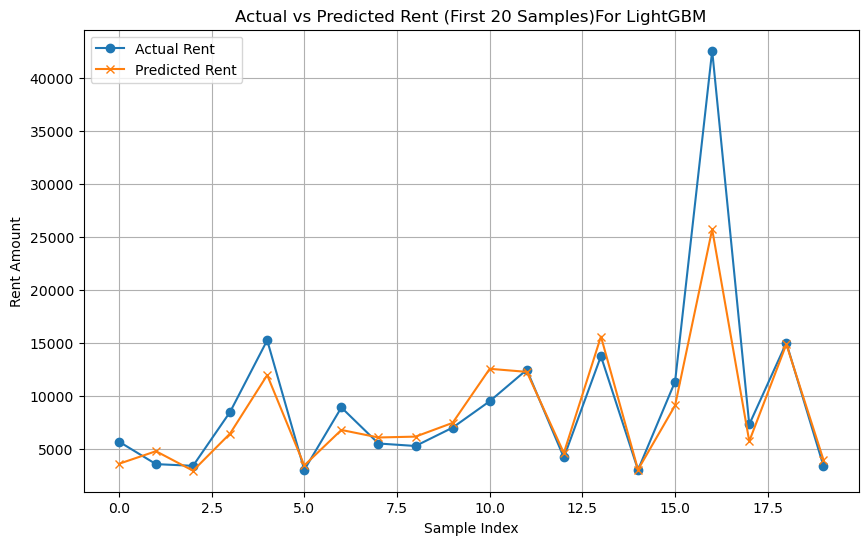

100%|██████████| 15/15 [00:18<00:00,  1.22s/it]


In [26]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [27]:
errors = pd.DataFrame(errors)

In [28]:
errors

,Linear Regression,Lasso,Ridge,KNN,SVM,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,2.109992e+03,2.109568e+03,2.108069e+03,1.761069e+03,2.009442e+03,3.215019e+02,6.743307e+02,0.000000e+00,6.871568e+02,2.757295e+03,8.552636e+02,6.154149e+02,2.364136e+02,7.010819e+02,6.092715e+02
MAE Test,1.993198e+03,1.992604e+03,1.992112e+03,2.222014e+03,2.073810e+03,2.032108e+03,1.662172e+03,1.324763e+03,1.723805e+03,3.107280e+03,1.392502e+03,1.299541e+03,1.406496e+03,1.219289e+03,1.247684e+03
MSE Train,8.887762e+06,8.887848e+06,8.888718e+06,7.822300e+06,1.282935e+07,3.743906e+05,1.007168e+06,0.000000e+00,1.071747e+06,1.119799e+07,1.373560e+06,1.132949e+06,1.036244e+05,9.100416e+05,1.142222e+06
MSE Test,9.703609e+06,9.707620e+06,9.723575e+06,1.403448e+07,1.498823e+07,1.371086e+07,8.107081e+06,4.915761e+06,8.103870e+06,1.846519e+07,4.812211e+06,5.272168e+06,6.434512e+06,4.499150e+06,5.024136e+06
RMSE Train,2.981235e+03,2.981249e+03,2.981395e+03,2.796838e+03,3.581808e+03,6.118747e+02,1.003577e+03,0.000000e+00,1.035252e+03,3.346340e+03,1.171990e+03,1.064401e+03,3.219075e+02,9.539610e+02,1.068748e+03
RMSE Test,3.115062e+03,3.115705e+03,3.118265e+03,3.746262e+03,3.871463e+03,3.702817e+03,2.847294e+03,2.217151e+03,2.846730e+03,4.297114e+03,2.193675e+03,2.296120e+03,2.536634e+03,2.121120e+03,2.241458e+03
R2 Train,7.728555e-01,7.728533e-01,7.728311e-01,8.000855e-01,6.721204e-01,9.904317e-01,9.742598e-01,1.000000e+00,9.726094e-01,7.138129e-01,9.648959e-01,9.710452e-01,9.973516e-01,9.767421e-01,9.708082e-01
R2 Test,7.649858e-01,7.648887e-01,7.645023e-01,6.600955e-01,6.369964e-01,6.679333e-01,8.036526e-01,8.809440e-01,8.037303e-01,5.527869e-01,8.834518e-01,8.723120e-01,8.441609e-01,8.910340e-01,8.783192e-01
